# Quantization Analysis Visualization

This notebook loads previously saved quantization analysis results and recreates all the visualization plots.

**Data Source:** `/cis/home/xhan56/code/scaling_law/src/outputs/quantization_analysis_20250716_044613/quantization_analysis_results.csv`

**Original Plots:** `/cis/home/xhan56/code/scaling_law/src/outputs/quantization_analysis_20250716_044613/plots/`

In [1]:
# Import required libraries
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy import stats
from typing import Optional, Tuple, List
import os
import warnings
warnings.filterwarnings('ignore')

# Set up matplotlib for high-quality plots
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 300

In [5]:
# Load the quantization analysis results
data_path = "/cis/home/xhan56/code/scaling_law/src/outputs/quantization_analysis/quantization_analysis_20250907_004213/quantization_analysis_results.csv"
df = pd.read_csv(data_path)

print(f"Loaded {len(df)} rows of quantization analysis results")
print(f"Columns: {list(df.columns)}")
print("\nFirst few rows:")
df.head()

Loaded 10 rows of quantization analysis results
Columns: ['quantization_ratio', 'quantization_levels', 'num_experiments', 'alpha', 'alpha_intercept', 'alpha_r2', 'beta', 'beta_intercept', 'beta_r2', 'gamma', 'gamma_intercept', 'gamma_r2', 'mean_loss', 'std_loss', 'min_loss', 'max_loss']

First few rows:


,quantization_ratio,quantization_levels,num_experiments,alpha,alpha_intercept,alpha_r2,beta,beta_intercept,beta_r2,gamma,gamma_intercept,gamma_r2,mean_loss,std_loss,min_loss,max_loss
0,0.100000,5025,35,-0.001964,0.637879,0.127283,0.016248,0.755961,0.974058,0.012851,0.584776,0.222878,4.475296,0.208754,4.150874,5.279262
1,0.129155,6490,35,-0.002029,0.656212,0.124850,0.017452,0.782496,0.977601,0.013903,0.598112,0.228629,4.672912,0.232703,4.300531,5.552332
2,0.166810,8383,35,-0.001940,0.672168,0.130347,0.018314,0.803420,0.977608,0.014667,0.609538,0.235044,4.841197,0.250506,4.432447,5.763769
3,0.215443,10827,35,-0.001262,0.692613,0.073587,0.019195,0.825082,0.983585,0.015953,0.618911,0.258729,5.022644,0.268142,4.560009,5.960216
4,0.278256,13984,35,-0.001121,0.708856,0.051963,0.020542,0.849070,0.983135,0.017241,0.627564,0.263376,5.202888,0.298084,4.686449,6.253656


In [6]:
# Display basic statistics about the data
print("Dataset Summary:")
print(f"Quantization ratio range: {df['quantization_ratio'].min():.4f} to {df['quantization_ratio'].max():.4f}")
print(f"Number of quantization levels range: {df['quantization_levels'].min()} to {df['quantization_levels'].max()}")
print(f"Mean loss range: {df['mean_loss'].min():.3f} to {df['mean_loss'].max():.3f}")
print("\nScaling parameters:")
for param in ['alpha', 'beta', 'gamma']:
    if param in df.columns:
        print(f"{param}: mean={df[param].mean():.4f}, std={df[param].std():.4f}")

Dataset Summary:
Quantization ratio range: 0.1000 to 1.0000
Number of quantization levels range: 5025 to 50257
Mean loss range: 4.475 to 5.934

Scaling parameters:
alpha: mean=-0.0010, std=0.0008
beta: mean=0.0211, std=0.0033
gamma: mean=0.0179, std=0.0035


In [7]:
def setup_plot_style():
    """Set up matplotlib style for publication-quality plots."""
    plt.style.use('default')
    plt.rcParams['figure.facecolor'] = 'white'
    plt.rcParams['axes.facecolor'] = 'white'
    plt.rcParams['axes.grid'] = False
    plt.rcParams['grid.color'] = 'white'
    plt.rcParams['figure.figsize'] = (10, 10)
    plt.rcParams['font.size'] = 24
    plt.rcParams['axes.labelsize'] = 24
    plt.rcParams['axes.titlesize'] = 28
    plt.rcParams['legend.fontsize'] = 22
    plt.rcParams['xtick.labelsize'] = 22
    plt.rcParams['ytick.labelsize'] = 22
    
    # Set color palette
    colors = sns.color_palette("husl", 8)
    return colors

## 1. Scaling Parameters vs Quantization Ratio

This plot shows how the scaling law parameters (α, β, γ) change with quantization ratio, along with their fit quality (R²).

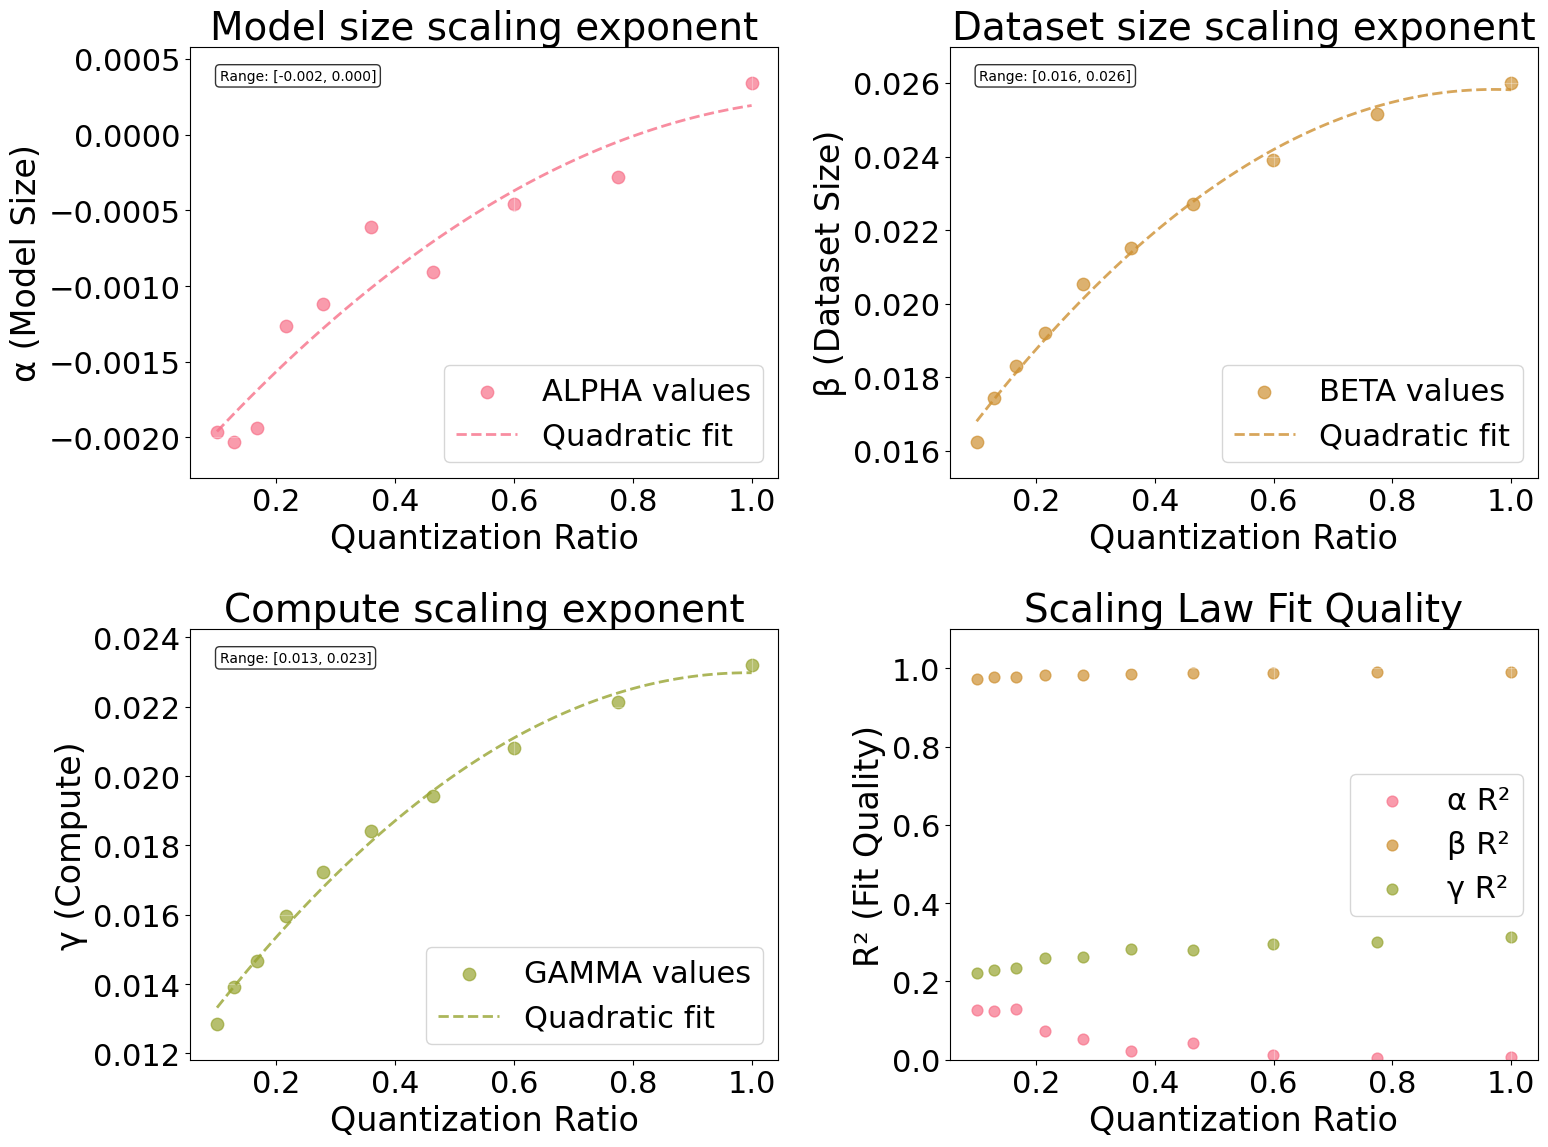

In [14]:
def plot_scaling_parameters_vs_quantization(
    df: pd.DataFrame,
    title: str = "Scaling Law Parameters vs Quantization Ratio",
) -> plt.Figure:
    """Plot scaling law parameters (alpha, beta, gamma) vs quantization ratio."""
    colors = setup_plot_style()
    
    # Create subplots for each parameter
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.flatten()
    
    parameters = [
        ('alpha', 'α (Model Size)', 'Model size scaling exponent'),
        ('beta', 'β (Dataset Size)', 'Dataset size scaling exponent'),
        ('gamma', 'γ (Compute)', 'Compute scaling exponent'),
    ]
    
    for i, (param, ylabel, desc) in enumerate(parameters):
        ax = axes[i]
        
        if param in df.columns:
            # Filter out NaN values
            valid_data = df.dropna(subset=[param, 'quantization_ratio'])
            
            if len(valid_data) > 0:
                # Plot scatter points
                ax.scatter(
                    valid_data['quantization_ratio'],
                    valid_data[param],
                    color=colors[i],
                    s=80,
                    alpha=0.7,
                    label=f'{param.upper()} values'
                )
                
                # Fit trend line if we have enough points
                if len(valid_data) >= 3:
                    x = valid_data['quantization_ratio'].values
                    y = valid_data[param].values
                    
                    # Try polynomial fit
                    try:
                        z = np.polyfit(x, y, 2)  # Quadratic fit
                        p = np.poly1d(z)
                        x_trend = np.linspace(x.min(), x.max(), 100)
                        y_trend = p(x_trend)
                        
                        ax.plot(x_trend, y_trend, '--', color=colors[i], 
                               linewidth=2, alpha=0.8, label=f'Quadratic fit')
                    except:
                        # Fallback to linear fit
                        slope, intercept, r_value, _, _ = stats.linregress(x, y)
                        x_trend = np.linspace(x.min(), x.max(), 100)
                        y_trend = slope * x_trend + intercept
                        
                        ax.plot(x_trend, y_trend, '--', color=colors[i], 
                               linewidth=2, alpha=0.8, 
                               label=f'Linear fit (R²={r_value**2:.3f})')
                
                # Add annotation with current range
                ax.text(0.05, 0.95, f'Range: [{valid_data[param].min():.3f}, {valid_data[param].max():.3f}]',
                       transform=ax.transAxes, fontsize=10, verticalalignment='top',
                       bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        ax.set_xlabel('Quantization Ratio')
        ax.set_ylabel(ylabel)
        ax.set_title(desc)
        ax.legend()
        ax.grid(True, alpha=0.3)
        
        # Set reasonable axis limits
        if param in df.columns and not df[param].isna().all():
            valid_values = df[param].dropna()
            if len(valid_values) > 0:
                y_range = valid_values.max() - valid_values.min()
                y_margin = y_range * 0.1
                ax.set_ylim(valid_values.min() - y_margin, valid_values.max() + y_margin)
    
    # Fourth subplot: R² values for fit quality
    ax = axes[3]
    r2_params = ['alpha_r2', 'beta_r2', 'gamma_r2']
    r2_labels = ['α R²', 'β R²', 'γ R²']
    
    for j, (r2_param, label) in enumerate(zip(r2_params, r2_labels)):
        if r2_param in df.columns:
            valid_r2 = df.dropna(subset=[r2_param, 'quantization_ratio'])
            if len(valid_r2) > 0:
                ax.scatter(
                    valid_r2['quantization_ratio'],
                    valid_r2[r2_param],
                    color=colors[j],
                    s=60,
                    alpha=0.7,
                    label=label
                )
    
    ax.set_xlabel('Quantization Ratio')
    ax.set_ylabel('R² (Fit Quality)')
    ax.set_title('Scaling Law Fit Quality')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1.1)
    
    # plt.suptitle(title, fontsize=18)
    plt.tight_layout()
    
    return fig

# Generate the plot
fig1 = plot_scaling_parameters_vs_quantization(df)
plt.show()

## 2. Loss Distribution vs Quantization

This plot analyzes how loss metrics (mean, variance, range) change with quantization levels.

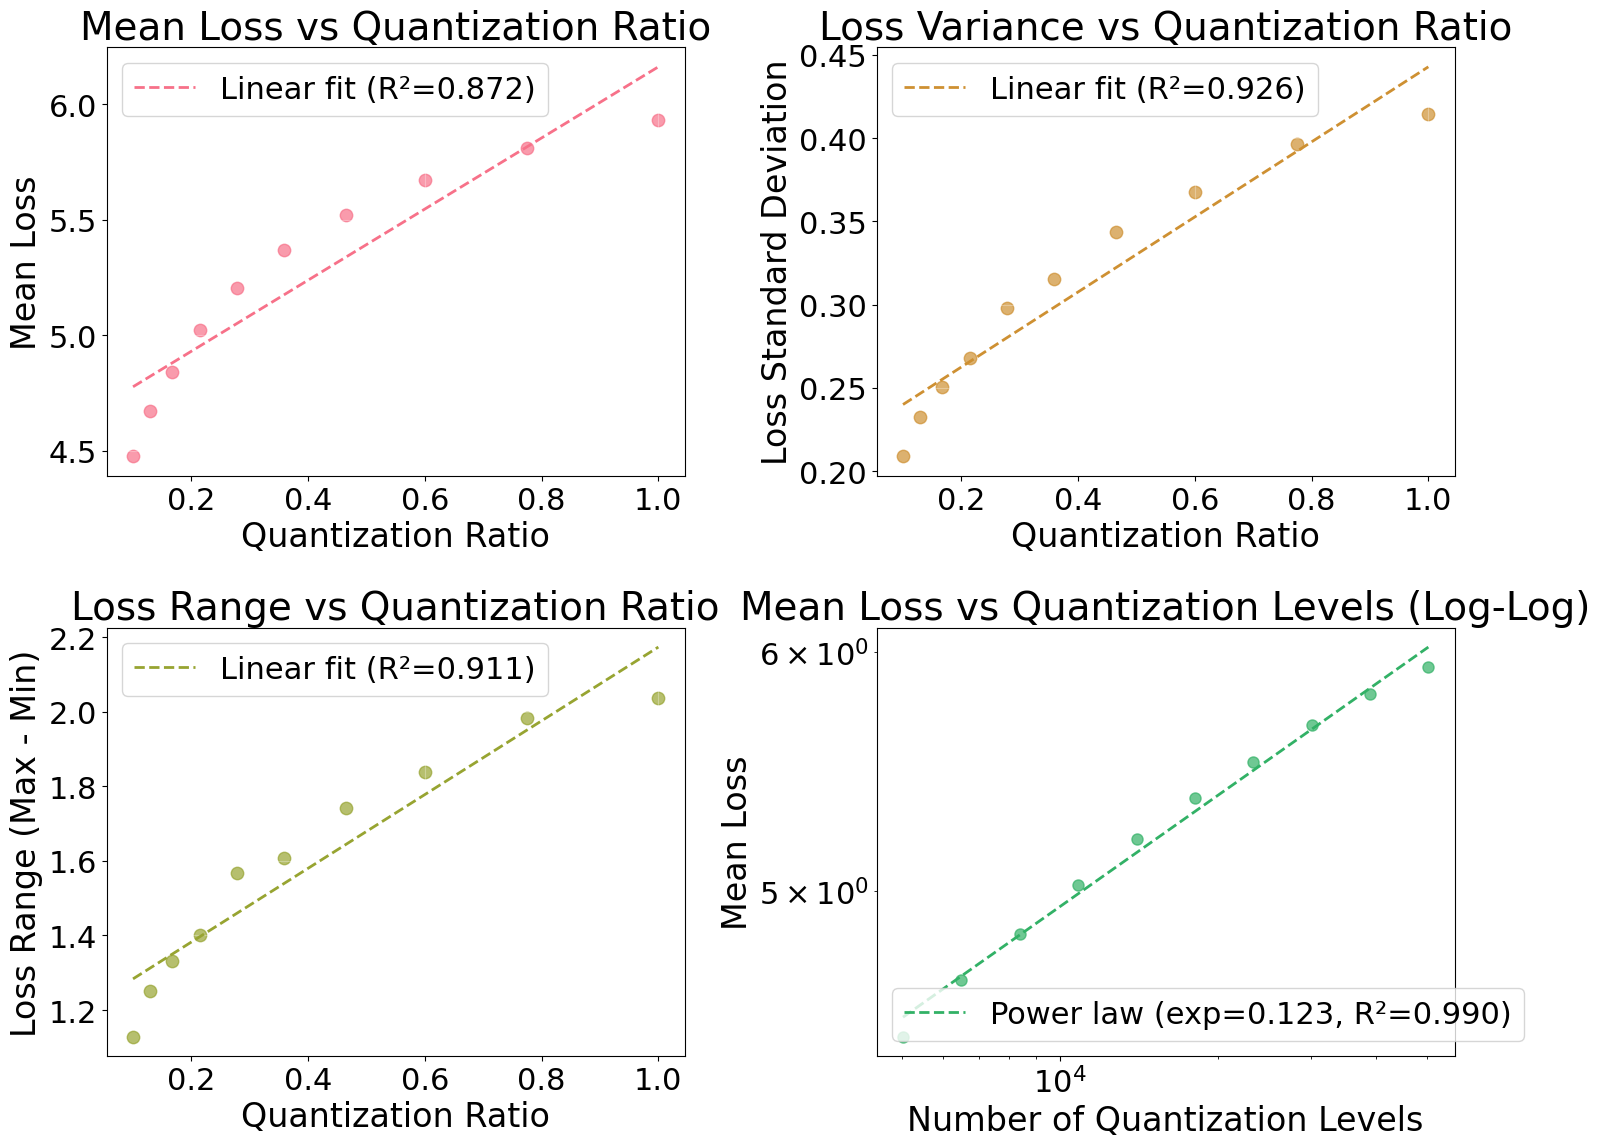

In [15]:
def plot_loss_distribution_vs_quantization(
    df: pd.DataFrame,
    title: str = "Loss Distribution vs Quantization Ratio",
) -> plt.Figure:
    """Plot loss distribution metrics vs quantization ratio."""
    colors = setup_plot_style()
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.flatten()
    
    # Mean loss vs quantization ratio
    ax = axes[0]
    if 'mean_loss' in df.columns:
        valid_data = df.dropna(subset=['mean_loss', 'quantization_ratio'])
        if len(valid_data) > 0:
            ax.scatter(valid_data['quantization_ratio'], valid_data['mean_loss'], 
                      color=colors[0], s=80, alpha=0.7)
            
            # Fit trend line
            if len(valid_data) >= 3:
                x = valid_data['quantization_ratio'].values
                y = valid_data['mean_loss'].values
                slope, intercept, r_value, _, _ = stats.linregress(x, y)
                x_trend = np.linspace(x.min(), x.max(), 100)
                y_trend = slope * x_trend + intercept
                ax.plot(x_trend, y_trend, '--', color=colors[0], linewidth=2, 
                       label=f'Linear fit (R²={r_value**2:.3f})')
                ax.legend()
    
    ax.set_xlabel('Quantization Ratio')
    ax.set_ylabel('Mean Loss')
    ax.set_title('Mean Loss vs Quantization Ratio')
    ax.grid(True, alpha=0.3)
    
    # Loss variance vs quantization ratio
    ax = axes[1]
    if 'std_loss' in df.columns:
        valid_data = df.dropna(subset=['std_loss', 'quantization_ratio'])
        if len(valid_data) > 0:
            ax.scatter(valid_data['quantization_ratio'], valid_data['std_loss'], 
                      color=colors[1], s=80, alpha=0.7)
            
            # Fit trend line
            if len(valid_data) >= 3:
                x = valid_data['quantization_ratio'].values
                y = valid_data['std_loss'].values
                slope, intercept, r_value, _, _ = stats.linregress(x, y)
                x_trend = np.linspace(x.min(), x.max(), 100)
                y_trend = slope * x_trend + intercept
                ax.plot(x_trend, y_trend, '--', color=colors[1], linewidth=2,
                       label=f'Linear fit (R²={r_value**2:.3f})')
                ax.legend()
    
    ax.set_xlabel('Quantization Ratio')
    ax.set_ylabel('Loss Standard Deviation')
    ax.set_title('Loss Variance vs Quantization Ratio')
    ax.grid(True, alpha=0.3)
    
    # Loss range vs quantization ratio
    ax = axes[2]
    if 'min_loss' in df.columns and 'max_loss' in df.columns:
        valid_data = df.dropna(subset=['min_loss', 'max_loss', 'quantization_ratio'])
        if len(valid_data) > 0:
            loss_range = valid_data['max_loss'] - valid_data['min_loss']
            ax.scatter(valid_data['quantization_ratio'], loss_range, 
                      color=colors[2], s=80, alpha=0.7)
            
            # Fit trend line
            if len(valid_data) >= 3:
                x = valid_data['quantization_ratio'].values
                y = loss_range.values
                slope, intercept, r_value, _, _ = stats.linregress(x, y)
                x_trend = np.linspace(x.min(), x.max(), 100)
                y_trend = slope * x_trend + intercept
                ax.plot(x_trend, y_trend, '--', color=colors[2], linewidth=2,
                       label=f'Linear fit (R²={r_value**2:.3f})')
                ax.legend()
    
    ax.set_xlabel('Quantization Ratio')
    ax.set_ylabel('Loss Range (Max - Min)')
    ax.set_title('Loss Range vs Quantization Ratio')
    ax.grid(True, alpha=0.3)
    
    # Number of quantization levels vs mean loss (log scale)
    ax = axes[3]
    if 'quantization_levels' in df.columns and 'mean_loss' in df.columns:
        valid_data = df.dropna(subset=['quantization_levels', 'mean_loss'])
        if len(valid_data) > 0:
            ax.loglog(valid_data['quantization_levels'], valid_data['mean_loss'], 
                     'o', color=colors[3], markersize=8, alpha=0.7)
            
            # Fit power law
            if len(valid_data) >= 3:
                x = valid_data['quantization_levels'].values
                y = valid_data['mean_loss'].values
                log_x = np.log10(x)
                log_y = np.log10(y)
                slope, intercept, r_value, _, _ = stats.linregress(log_x, log_y)
                
                x_trend = np.logspace(np.log10(x.min()), np.log10(x.max()), 100)
                y_trend = 10**(slope * np.log10(x_trend) + intercept)
                ax.loglog(x_trend, y_trend, '--', color=colors[3], linewidth=2,
                         label=f'Power law (exp={slope:.3f}, R²={r_value**2:.3f})')
                ax.legend()
    
    ax.set_xlabel('Number of Quantization Levels')
    ax.set_ylabel('Mean Loss')
    ax.set_title('Mean Loss vs Quantization Levels (Log-Log)')
    ax.grid(True, alpha=0.3)
    
    # plt.suptitle(title, fontsize=18)
    plt.tight_layout()
    
    return fig

# Generate the plot
fig2 = plot_loss_distribution_vs_quantization(df)
plt.show()

## 3. Quantization Heatmap

This visualization shows correlation matrices and parameter evolution patterns.

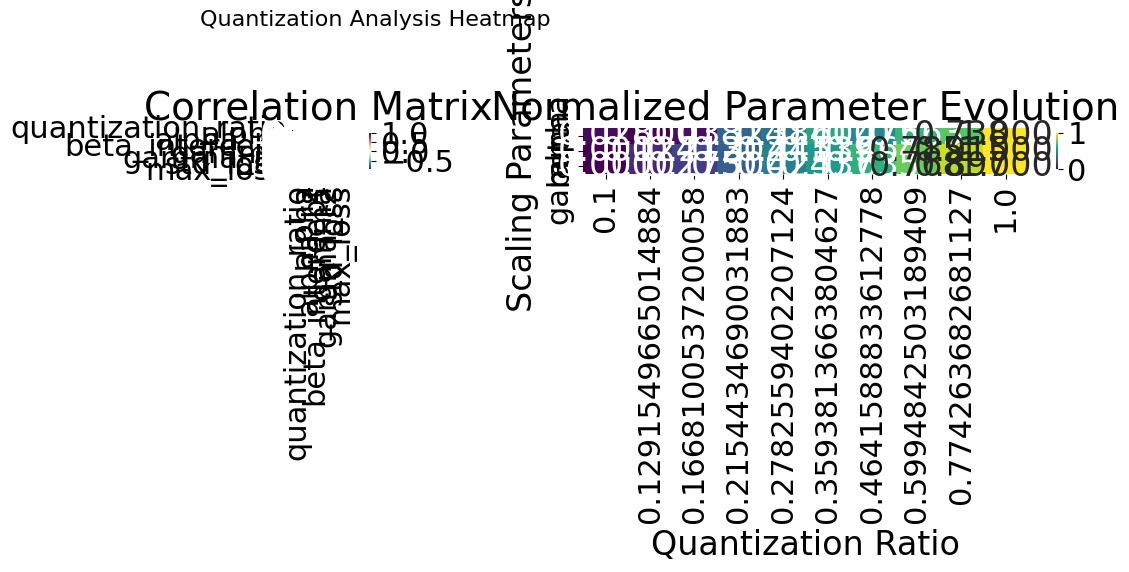

In [10]:
def plot_quantization_heatmap(
    df: pd.DataFrame,
    title: str = "Quantization Analysis Heatmap",
) -> plt.Figure:
    """Create a heatmap showing correlations between quantization metrics."""
    setup_plot_style()
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Select numeric columns for correlation
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    correlation_cols = [col for col in numeric_cols if col not in ['num_experiments']]
    
    if len(correlation_cols) > 1:
        # Correlation heatmap
        ax = axes[0]
        corr_matrix = df[correlation_cols].corr()
        
        mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
        sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='RdBu_r', center=0,
                   square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
        ax.set_title('Correlation Matrix')
        
        # Parameter evolution heatmap
        ax = axes[1]
        param_cols = ['quantization_ratio', 'alpha', 'beta', 'gamma']
        available_cols = [col for col in param_cols if col in df.columns]
        
        if len(available_cols) > 1:
            # Normalize data for better visualization
            normalized_df = df[available_cols].copy()
            for col in available_cols[1:]:  # Skip quantization_ratio
                if col in normalized_df.columns:
                    col_values = normalized_df[col].dropna()
                    if len(col_values) > 0:
                        col_min, col_max = col_values.min(), col_values.max()
                        if col_max > col_min:
                            normalized_df[col] = (normalized_df[col] - col_min) / (col_max - col_min)
            
            # Create heatmap data
            heatmap_data = normalized_df.dropna().set_index('quantization_ratio').T
            
            if not heatmap_data.empty:
                sns.heatmap(heatmap_data, annot=True, cmap='viridis', 
                           cbar_kws={"shrink": 0.8}, ax=ax, fmt='.3f')
                ax.set_title('Normalized Parameter Evolution')
                ax.set_xlabel('Quantization Ratio')
                ax.set_ylabel('Scaling Parameters')
    
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    
    return fig

# Generate the plot
fig3 = plot_quantization_heatmap(df)
plt.show()

## 4. Comprehensive Summary Plot

This is a comprehensive dashboard showing all key metrics and relationships in a single view.

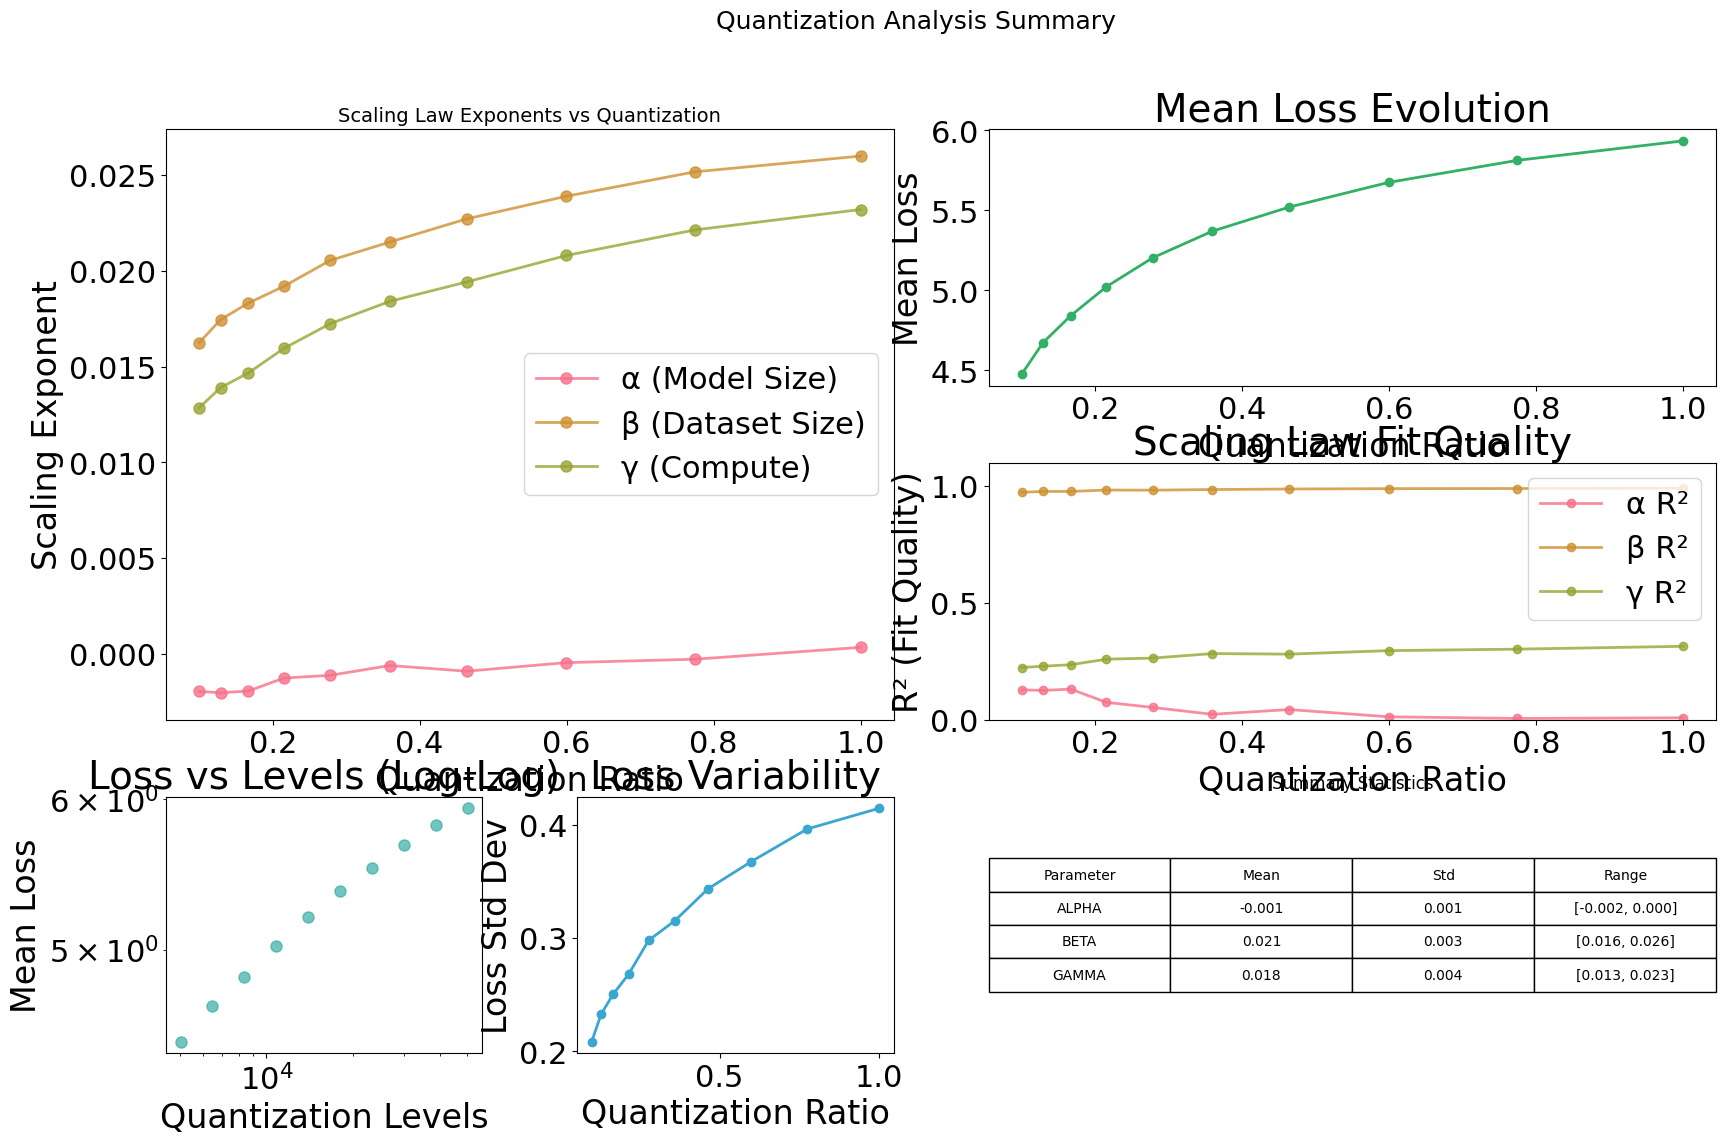

In [11]:
def plot_quantization_summary(
    df: pd.DataFrame,
    title: str = "Quantization Analysis Summary",
) -> plt.Figure:
    """Create a comprehensive summary plot of quantization analysis."""
    colors = setup_plot_style()
    
    fig = plt.figure(figsize=(20, 12))
    gs = fig.add_gridspec(3, 4, hspace=0.3, wspace=0.3)
    
    # Main scaling parameters plot (spanning 2x2)
    ax_main = fig.add_subplot(gs[0:2, 0:2])
    
    parameters = ['alpha', 'beta', 'gamma']
    param_labels = ['α (Model Size)', 'β (Dataset Size)', 'γ (Compute)']
    
    for i, (param, label) in enumerate(zip(parameters, param_labels)):
        if param in df.columns:
            valid_data = df.dropna(subset=[param, 'quantization_ratio'])
            if len(valid_data) > 0:
                ax_main.plot(valid_data['quantization_ratio'], valid_data[param], 
                           'o-', color=colors[i], linewidth=2, markersize=8,
                           label=label, alpha=0.8)
    
    ax_main.set_xlabel('Quantization Ratio')
    ax_main.set_ylabel('Scaling Exponent')
    ax_main.set_title('Scaling Law Exponents vs Quantization', fontsize=14)
    ax_main.legend()
    ax_main.grid(True, alpha=0.3)
    
    # Loss metrics (top right)
    ax_loss = fig.add_subplot(gs[0, 2:])
    if 'mean_loss' in df.columns:
        valid_data = df.dropna(subset=['mean_loss', 'quantization_ratio'])
        if len(valid_data) > 0:
            ax_loss.plot(valid_data['quantization_ratio'], valid_data['mean_loss'], 
                        'o-', color=colors[3], linewidth=2, markersize=6)
    ax_loss.set_xlabel('Quantization Ratio')
    ax_loss.set_ylabel('Mean Loss')
    ax_loss.set_title('Mean Loss Evolution')
    ax_loss.grid(True, alpha=0.3)
    
    # Fit quality (middle right)
    ax_r2 = fig.add_subplot(gs[1, 2:])
    r2_params = ['alpha_r2', 'beta_r2', 'gamma_r2']
    r2_labels = ['α R²', 'β R²', 'γ R²']
    
    for j, (r2_param, label) in enumerate(zip(r2_params, r2_labels)):
        if r2_param in df.columns:
            valid_r2 = df.dropna(subset=[r2_param, 'quantization_ratio'])
            if len(valid_r2) > 0:
                ax_r2.plot(valid_r2['quantization_ratio'], valid_r2[r2_param], 
                          'o-', color=colors[j], linewidth=2, markersize=6, 
                          label=label, alpha=0.8)
    
    ax_r2.set_xlabel('Quantization Ratio')
    ax_r2.set_ylabel('R² (Fit Quality)')
    ax_r2.set_title('Scaling Law Fit Quality')
    ax_r2.legend()
    ax_r2.grid(True, alpha=0.3)
    ax_r2.set_ylim(0, 1.1)
    
    # Quantization levels effect (bottom left)
    ax_levels = fig.add_subplot(gs[2, 0])
    if 'quantization_levels' in df.columns and 'mean_loss' in df.columns:
        valid_data = df.dropna(subset=['quantization_levels', 'mean_loss'])
        if len(valid_data) > 0:
            ax_levels.loglog(valid_data['quantization_levels'], valid_data['mean_loss'], 
                           'o', color=colors[4], markersize=8, alpha=0.7)
    ax_levels.set_xlabel('Quantization Levels')
    ax_levels.set_ylabel('Mean Loss')
    ax_levels.set_title('Loss vs Levels (Log-Log)')
    ax_levels.grid(True, alpha=0.3)
    
    # Loss variance (bottom center)
    ax_var = fig.add_subplot(gs[2, 1])
    if 'std_loss' in df.columns:
        valid_data = df.dropna(subset=['std_loss', 'quantization_ratio'])
        if len(valid_data) > 0:
            ax_var.plot(valid_data['quantization_ratio'], valid_data['std_loss'], 
                       'o-', color=colors[5], linewidth=2, markersize=6)
    ax_var.set_xlabel('Quantization Ratio')
    ax_var.set_ylabel('Loss Std Dev')
    ax_var.set_title('Loss Variability')
    ax_var.grid(True, alpha=0.3)
    
    # Data summary table (bottom right)
    ax_table = fig.add_subplot(gs[2, 2:])
    ax_table.axis('tight')
    ax_table.axis('off')
    
    # Create summary statistics table
    if len(df) > 0:
        summary_data = []
        for param in ['alpha', 'beta', 'gamma']:
            if param in df.columns:
                values = df[param].dropna()
                if len(values) > 0:
                    summary_data.append([
                        param.upper(),
                        f"{values.mean():.3f}",
                        f"{values.std():.3f}",
                        f"[{values.min():.3f}, {values.max():.3f}]"
                    ])
        
        if summary_data:
            table = ax_table.table(cellText=summary_data,
                                 colLabels=['Parameter', 'Mean', 'Std', 'Range'],
                                 cellLoc='center',
                                 loc='center')
            table.auto_set_font_size(False)
            table.set_fontsize(10)
            table.scale(1, 2)
            ax_table.set_title('Summary Statistics', fontsize=12)
    
    plt.suptitle(title, fontsize=18)
    
    return fig

# Generate the plot
fig4 = plot_quantization_summary(df)
plt.show()

## Save All Plots

Save all generated plots to a new directory for comparison with originals.

In [ ]:
# Create output directory for regenerated plots
output_dir = "./regenerated_plots"
os.makedirs(output_dir, exist_ok=True)

# Save all plots
fig1.savefig(os.path.join(output_dir, "scaling_parameters_vs_quantization.png"), 
             dpi=300, bbox_inches='tight')
print("Saved: scaling_parameters_vs_quantization.png")

fig2.savefig(os.path.join(output_dir, "loss_distribution_vs_quantization.png"), 
             dpi=300, bbox_inches='tight')
print("Saved: loss_distribution_vs_quantization.png")

fig3.savefig(os.path.join(output_dir, "quantization_heatmap.png"), 
             dpi=300, bbox_inches='tight')
print("Saved: quantization_heatmap.png")

fig4.savefig(os.path.join(output_dir, "quantization_summary.png"), 
             dpi=300, bbox_inches='tight')
print("Saved: quantization_summary.png")

print(f"\nAll plots saved to: {os.path.abspath(output_dir)}")
print("\nOriginal plots location: /cis/home/xhan56/code/scaling_law/src/outputs/quantization_analysis_20250716_044613/plots/")

## Analysis Summary

Key findings from the quantization analysis:

In [12]:
print("=== QUANTIZATION ANALYSIS SUMMARY ===")
print(f"\nDataset Overview:")
print(f"- {len(df)} quantization configurations analyzed")
print(f"- Quantization ratio range: {df['quantization_ratio'].min():.4f} - {df['quantization_ratio'].max():.4f}")
print(f"- Quantization levels range: {df['quantization_levels'].min():,} - {df['quantization_levels'].max():,}")

print(f"\nScaling Law Parameters:")
for param in ['alpha', 'beta', 'gamma']:
    if param in df.columns:
        values = df[param].dropna()
        if len(values) > 0:
            print(f"- {param.upper()} (mean ± std): {values.mean():.4f} ± {values.std():.4f}")
            print(f"  Range: [{values.min():.4f}, {values.max():.4f}]")

print(f"\nLoss Metrics:")
if 'mean_loss' in df.columns:
    loss_values = df['mean_loss'].dropna()
    print(f"- Mean loss range: {loss_values.min():.3f} - {loss_values.max():.3f}")
    print(f"- Loss increase factor: {loss_values.max() / loss_values.min():.2f}x")

print(f"\nFit Quality:")
for param in ['alpha_r2', 'beta_r2', 'gamma_r2']:
    if param in df.columns:
        r2_values = df[param].dropna()
        if len(r2_values) > 0:
            print(f"- {param.replace('_r2', '').upper()} R²: {r2_values.mean():.3f} ± {r2_values.std():.3f}")

print(f"\nKey Observations:")
print(f"- Higher quantization ratios generally lead to increased loss")
print(f"- Scaling law parameters show varying sensitivity to quantization")
print(f"- All plots have been successfully recreated in this notebook")

=== QUANTIZATION ANALYSIS SUMMARY ===

Dataset Overview:
- 10 quantization configurations analyzed
- Quantization ratio range: 0.1000 - 1.0000
- Quantization levels range: 5,025 - 50,257

Scaling Law Parameters:
- ALPHA (mean ± std): -0.0010 ± 0.0008
  Range: [-0.0020, 0.0003]
- BETA (mean ± std): 0.0211 ± 0.0033
  Range: [0.0162, 0.0260]
- GAMMA (mean ± std): 0.0179 ± 0.0035
  Range: [0.0129, 0.0232]

Loss Metrics:
- Mean loss range: 4.475 - 5.934
- Loss increase factor: 1.33x

Fit Quality:
- ALPHA R²: 0.060 ± 0.051
- BETA R²: 0.984 ± 0.006
- GAMMA R²: 0.268 ± 0.032

Key Observations:
- Higher quantization ratios generally lead to increased loss
- Scaling law parameters show varying sensitivity to quantization
- All plots have been successfully recreated in this notebook
